In [60]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv


In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv")
print(df.shape)
df.head()

(1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [62]:
df.info()
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
Missing values:
 gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score             

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [63]:
df.columns = ["gender", "race", "parent_edu", "lunch", "test_prep",
              "math", "reading", "writing"]
df["total"] = df["math"] + df["reading"] + df["writing"]
df["average"] = (df["total"] / 3).round(1)
df.head()

,gender,race,parent_edu,lunch,test_prep,math,reading,writing,total,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.7
1,female,group C,some college,standard,completed,69,90,88,247,82.3
2,female,group B,master's degree,standard,none,90,95,93,278,92.7
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.3
4,male,group C,some college,standard,none,76,78,75,229,76.3


## Dataset Summary
1. The dataset has 1,000 rows and 8 columns, with one row per student.
2. Columns: gender, race/ethnicity group (A to E), parental level of education,
   lunch type (standard or free/reduced), test preparation course (completed or
   none), and math, reading and writing scores.
3. Five columns are text categories and three score columns are integers.
   I renamed the columns to shorter names and added "total" and "average"
   columns for analysis.
4. There are 0 missing values and 0 duplicate rows, so no cleaning was needed.
5. Scores range from 0 to 100 in math (mean 66.1), 17 to 100 in reading
   (mean 69.2) and 10 to 100 in writing (mean 68.1). A few very low scores
   were kept because they are valid student results.

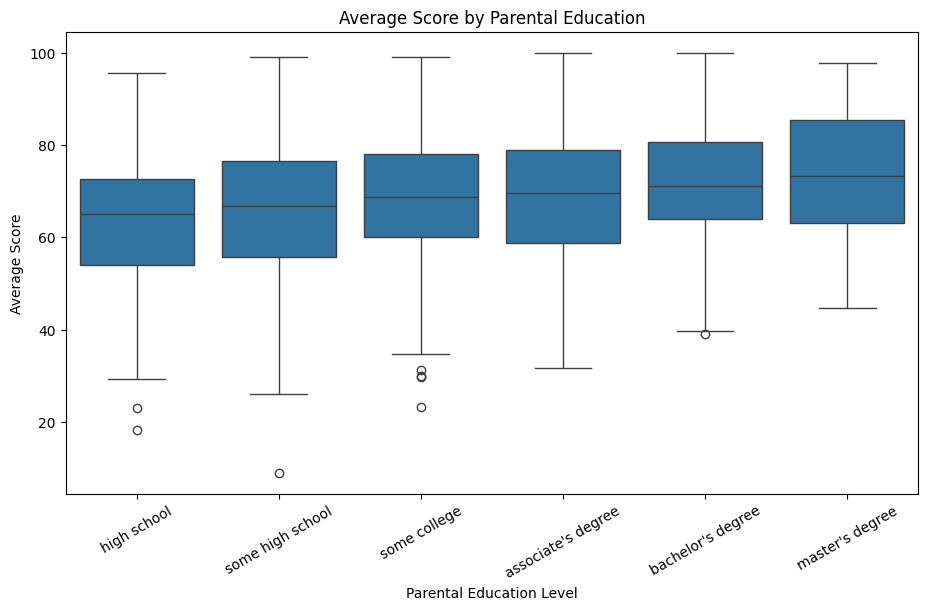

In [64]:
# Q1: Does parental education affect scores?
q1 = df.groupby("parent_edu")[["math","reading","writing","average"]].mean().round(1).sort_values("average")
q1


# Chart 1: Box plot - scores by parental education
order = q1.index
plt.figure(figsize=(11,6))
sns.boxplot(data=df, x="parent_edu", y="average", order=order)
plt.title("Average Score by Parental Education")
plt.xlabel("Parental Education Level")
plt.ylabel("Average Score")
plt.xticks(rotation=30)
plt.show()

**Q1: Does parental education affect scores?**
Yes. Average score rises steadily with parental education, from 63.1 (high
school) to 73.6 (master's degree), a gap of 10.5 points. The gap is largest in
writing (62.4 to 75.7) and smallest in math (62.1 to 69.7)

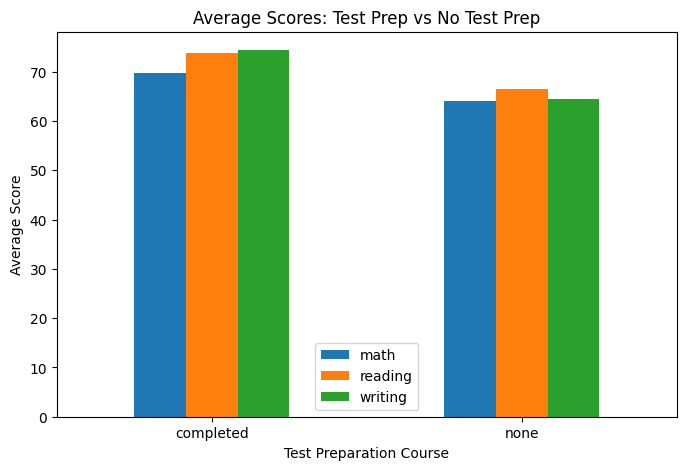

In [65]:
# Q2: Do students who complete test prep score higher?
q2 = df.groupby("test_prep")[["math","reading","writing","average"]].mean().round(1)
q2

# Chart 2: Bar chart - test prep comparison
q2.drop(columns="average").plot(kind="bar", figsize=(8,5))
plt.title("Average Scores: Test Prep vs No Test Prep")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.show()

**Q2: Do students who complete test prep score higher?**
Yes. Students who completed test prep average 72.7 versus 65.0 for those who
did not, a gap of 7.7 points. The gap shows in all three subjects: math
(69.7 vs 64.1), reading (73.9 vs 66.5) and writing (74.4 vs 64.5).

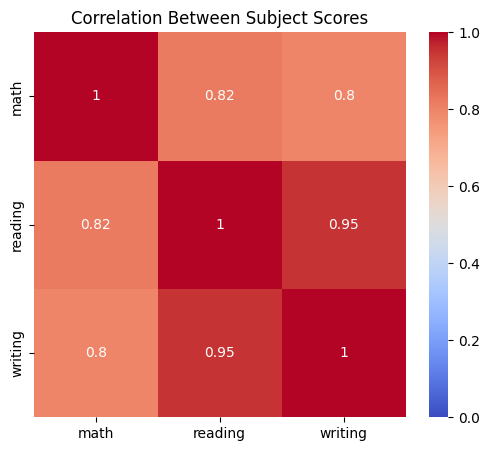

In [66]:
# Q3: Correlation between reading, writing and math
q3 = df[["math","reading","writing"]].corr().round(2)
q3


# Chart 3: Correlation heatmap
plt.figure(figsize=(6,5))
sns.heatmap(q3, annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Correlation Between Subject Scores")
plt.show()

**Q3: How are the subjects related?**
All three are strongly correlated. Reading and writing are almost
interchangeable (0.95), and math is also strongly linked to reading (0.82)
and writing (0.80). A student who is strong in one subject is usually strong
in the others.

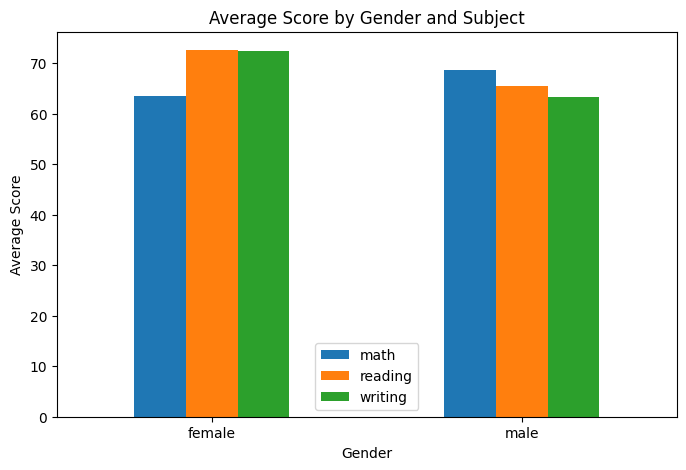

In [67]:
# Q4: Which gender performs better in which subject?
q4 = df.groupby("gender")[["math","reading","writing"]].mean().round(1)
q4


# Chart 4: Grouped bar - gender vs subject
q4.plot(kind="bar", figsize=(8,5))
plt.title("Average Score by Gender and Subject")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.show()

**Q4: Which gender performs better in which subject?**
Females score higher in reading (72.6 vs 65.5) and writing (72.5 vs 63.3).
Males score higher in math (68.7 vs 63.6). The female advantage in writing
(9.2 points) is the largest gap

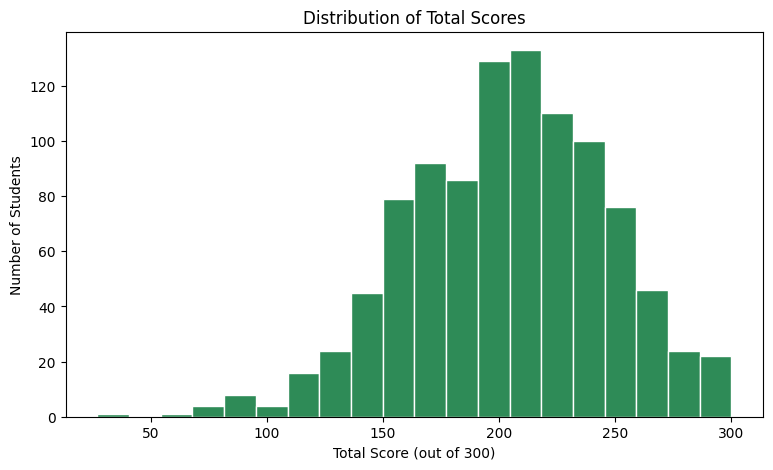

In [68]:
# Q5: Distribution of total scores
df["total"].describe().round(1)



# Chart 5: Histogram - total score distribution
plt.figure(figsize=(9,5))
plt.hist(df["total"], bins=20, color="seagreen", edgecolor="white")
plt.title("Distribution of Total Scores")
plt.xlabel("Total Score (out of 300)")
plt.ylabel("Number of Students")
plt.show()

**Q5: How are total scores distributed?**
Total scores (out of 300) have a mean of 203.3 and a median of 205, with a
standard deviation of 42.8. The middle 50% of students score between 175 and
233. The minimum is 27 and the maximum is 300. The median is slightly above
the mean, which suggests a small group of very low scorers pulls the average
down.

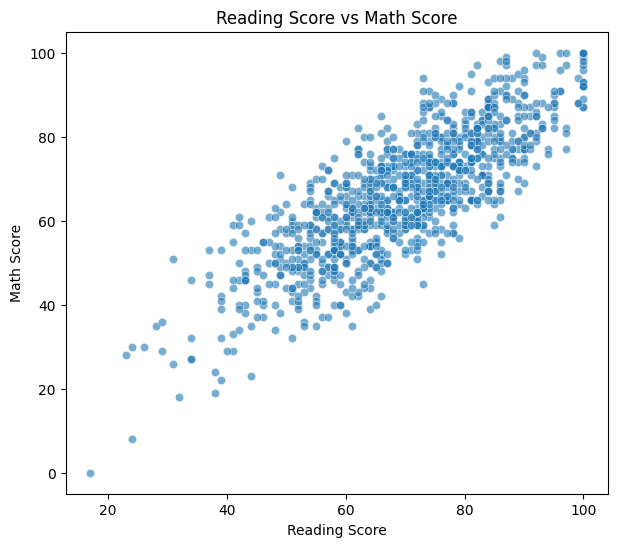

In [69]:
# Chart 6: Scatter plot - reading vs math
plt.figure(figsize=(7,6))
sns.scatterplot(data=df, x="reading", y="math", alpha=0.6)
plt.title("Reading Score vs Math Score")
plt.xlabel("Reading Score")
plt.ylabel("Math Score")
plt.show()

In [70]:
df["at_risk"] = df[["math","reading","writing"]].min(axis=1) < 50
n_risk = df["at_risk"].sum()
print("At-risk students:", n_risk, "of", len(df), f"({n_risk/len(df)*100:.1f}%)")

At-risk students: 188 of 1000 (18.8%)


In [71]:
rows = []
for col in ["gender", "race", "parent_edu", "lunch", "test_prep"]:
    g = df.groupby(col)["at_risk"].agg(students="count", at_risk="sum")
    g["at_risk_%"] = (g["at_risk"] / g["students"] * 100).round(1)
    g = g.reset_index().rename(columns={col: "group"})
    g.insert(0, "factor", col)
    rows.append(g)

risk_table = pd.concat(rows).sort_values("at_risk_%", ascending=False)
risk_table

,factor,group,students,at_risk,at_risk_%
0,race,group A,89,30,33.7
0,lunch,free/reduced,355,111,31.3
5,parent_edu,some high school,179,46,25.7
2,parent_edu,high school,196,49,25.0
1,test_prep,none,642,152,23.7
1,race,group B,190,43,22.6
1,gender,male,482,99,20.5
2,race,group C,319,59,18.5
0,gender,female,518,89,17.2
4,parent_edu,some college,226,38,16.8


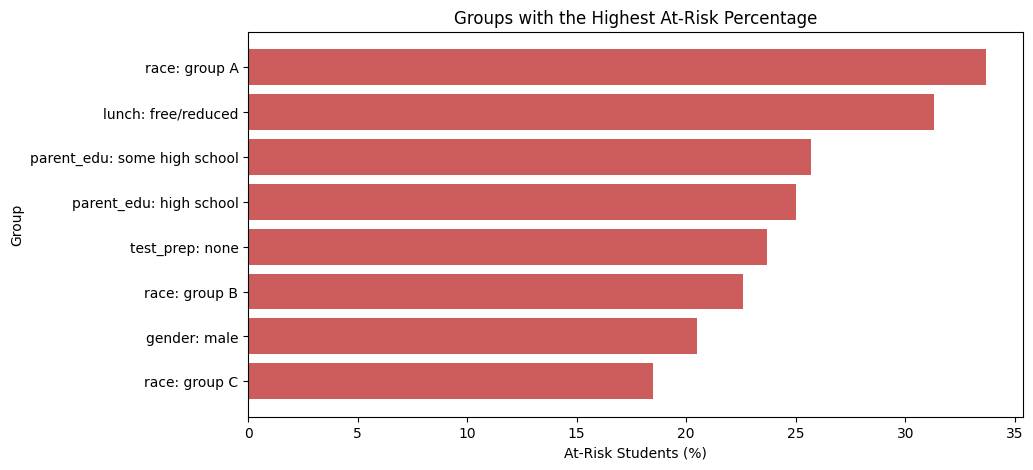

In [72]:
top = risk_table.head(8)
plt.figure(figsize=(10,5))
plt.barh(top["factor"] + ": " + top["group"], top["at_risk_%"], color="indianred")
plt.gca().invert_yaxis()
plt.title("Groups with the Highest At-Risk Percentage")
plt.xlabel("At-Risk Students (%)")
plt.ylabel("Group")
plt.show()

## At-Risk Analysis

- Definition: a student is at-risk if they score below 50 in any subject.
- 188 of 1,000 students (18.8%) are at-risk.
- The groups with the highest at-risk percentage are race group A (33.7%),
  free/reduced lunch (31.3%), and students whose parents completed only some
  high school (25.7%) or high school (25.0%). Students who did not take the
  test prep course are also higher (23.7%).
- Gender: males (20.5%) are at slightly higher risk than females (17.2%).
- Group A has only 89 students, so its percentage is less reliable than
  larger groups such as free/reduced lunch (355 students).
- Possible reasons (association, not proof of cause): free/reduced lunch may
  reflect lower family income and fewer study resources; parents with less
  education may be able to give less academic support at home; students
  without test prep had less structured practice. Q1 and Q2 show the same
  pattern: lower parental education and no test prep go with lower average
  scores.
- These factors overlap (for example, a student can be on free lunch and
  have skipped test prep), so the table cannot show which factor matters
  most on its own.

## Principal's Report

**Executive Summary**
We analysed the exam results of 1,000 students in math, reading and writing.
Parental education, test preparation and lunch type are all linked to
performance, and 188 students (18.8%) scored below 50 in at least one
subject. Targeted support for these groups could reduce the number of
at-risk students.

**Key Findings**
1. Parental education: average score rises from 63.1 (high school) to 73.6
   (master's degree), a gap of 10.5 points (Chart 1).
2. Test prep: students who completed it average 72.7 versus 65.0 for those
   who did not, a gap of 7.7 points (Chart 2).
3. Subjects move together: reading and writing correlate at 0.95, and math
   correlates at 0.82 with reading (Chart 3).
4. Gender: females lead in reading (72.6 vs 65.5) and writing (72.5 vs 63.3),
   while males lead in math (68.7 vs 63.6) (Chart 4).
5. At-risk students: 18.8% overall, highest among free/reduced lunch
   students (31.3%) and those with no test prep (23.7%) (at-risk table).

**Recommendations**
1. Offer the test prep course free to all students on free/reduced lunch.
   These students are at highest risk (31.3%) and the course is linked to
   a 7.7-point higher average.
2. Run early tutoring in the first term for students whose parents did not
   go beyond high school, since they are about 25% at-risk.
3. Add a math support programme for male students and a reading and writing
   programme for female students, based on each group's weaker subject.

## Most Impactful Recommendation

The most impactful recommendation is free test prep for students on
free/reduced lunch. This group is the largest high-risk group (355 students,
31.3% at-risk), and students who completed test prep score 7.7 points higher
on average. The data shows association rather than proof of cause, so I would
run it as a pilot for one term and compare at-risk rates afterwards. If it
works, the number of at-risk students in this group should fall.